In [ ]:
# CatBoost のインストールを確認
import catboost

print(catboost.__version__)

1.2.10


## ライブラリの読み込み

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

from catboost import CatBoostClassifier

## データ読み込み

In [3]:
ROOT = Path.cwd()

if ROOT.name == "smartphone_addiction":
    ROOT = ROOT.parent.parent

DATA_DIR = ROOT / "data" / "smartphone_addiction" / "raw"
OUTPUT_DIR = ROOT / "output" / "smartphone_addiction"

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(
    DATA_DIR / "sample_submission.csv"
)

print("train:", train.shape)
print("test :", test.shape)

train: (691369, 14)
test : (296302, 13)


## X , y を作成

In [4]:
TARGET = "addicted_label"

X = train.drop(columns=[TARGET, "id"]).copy()
y = train[TARGET].copy()

X_test = test.drop(columns=["id"]).copy()

## カテゴリ列を確認

In [5]:
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("numeric:")
print(numeric_cols)

print()

print("categorical:")
print(categorical_cols)

numeric:
['age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time']

categorical:
['gender', 'stress_level', 'academic_work_impact']


C:\Users\Owner\AppData\Local\Temp\ipykernel_7488\2105545832.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(


In [6]:
# CatBoost では、カテゴリ列をそのまま扱えるため、One-Hot Encoding は行わない
# ただし、カテゴリ列の "NaN" だけ "Missing" としておく
# 数値列の "NaN" はそのままで ok
for col in categorical_cols:
    X[col] = X[col].fillna("Missing").astype(str)
    X_test[col] = X_test[col].fillna("Missing").astype(str)

## 3-fold CV を作成

In [7]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

## モデル
CatBoostには Early Stopping という機能があり、validation AUC がこれ以上改善しないとなると、自動で途中でも学習を終了してくれる。

In [33]:
# iteration を何回に設定すればよいかの確認
train_idx, valid_idx = next(cv.split(X, y))

X_train = X.iloc[train_idx]
X_valid = X.iloc[valid_idx]

y_train = y.iloc[train_idx]
y_valid = y.iloc[valid_idx]

model = CatBoostClassifier(
    iterations=7000,
    learning_rate=0.05,
    depth=7,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

model.fit(
    X_train,
    y_train,
    cat_features=categorical_cols,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100
)

0:	test: 0.9095252	best: 0.9095252 (0)	total: 255ms	remaining: 29m 42s
100:	test: 0.9368950	best: 0.9368950 (100)	total: 22.3s	remaining: 25m 26s
200:	test: 0.9429172	best: 0.9429172 (200)	total: 43.7s	remaining: 24m 38s
300:	test: 0.9473505	best: 0.9473505 (300)	total: 1m 4s	remaining: 24m 4s
400:	test: 0.9505061	best: 0.9505061 (400)	total: 1m 27s	remaining: 23m 52s
500:	test: 0.9528607	best: 0.9528607 (500)	total: 1m 49s	remaining: 23m 35s
600:	test: 0.9545177	best: 0.9545177 (600)	total: 2m 11s	remaining: 23m 17s
700:	test: 0.9557432	best: 0.9557432 (700)	total: 2m 33s	remaining: 22m 59s
800:	test: 0.9568040	best: 0.9568040 (800)	total: 2m 55s	remaining: 22m 38s
900:	test: 0.9577198	best: 0.9577198 (900)	total: 3m 17s	remaining: 22m 17s
1000:	test: 0.9583468	best: 0.9583468 (1000)	total: 3m 39s	remaining: 21m 57s
1100:	test: 0.9589085	best: 0.9589085 (1100)	total: 4m 2s	remaining: 21m 36s
1200:	test: 0.9594063	best: 0.9594063 (1200)	total: 4m 24s	remaining: 21m 18s
1300:	test: 0.95

CatBoostClassifier(allow_writing_files=False, depth=7, eval_metric='AUC', iterations=7000, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [34]:
print("best iteration:", model.get_best_iteration())
print("best score:", model.get_best_score())

best iteration: 5793
best score: {'learn': {'Logloss': 0.18701636284878387}, 'validation': {'Logloss': 0.2223971499797163, 'AUC': 0.9630441274379675}}


In [35]:
# １度目の実行ではこちらの設定で頭打ちになってしまい、まだ改善の余地があったと思われるため、
# iterations 1000 → 2000 に変更
# 2000 でも頭打ちになってしまったため、→ 3000
catboost_scores = []
best_iterations = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X, y),
    start=1
):
    print(f"\n===== Fold {fold} =====")

    X_train = X.iloc[train_idx]
    X_valid = X.iloc[valid_idx]

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    model = CatBoostClassifier(
        iterations=6000,
        learning_rate=0.05,
        depth=7,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42,
        verbose=100,
        allow_writing_files=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_cols,
        eval_set=(X_valid, y_valid),
        early_stopping_rounds=100
    )

    valid_pred = model.predict_proba(
        X_valid
    )[:, 1]

    score = roc_auc_score(
        y_valid,
        valid_pred
    )

    catboost_scores.append(score)
    best_iterations.append(
        model.get_best_iteration()
    )

    print(
        f"Fold {fold} AUC: {score:.6f}"
    )


===== Fold 1 =====
0:	test: 0.9095252	best: 0.9095252 (0)	total: 283ms	remaining: 28m 17s
100:	test: 0.9368950	best: 0.9368950 (100)	total: 24.1s	remaining: 23m 29s
200:	test: 0.9429172	best: 0.9429172 (200)	total: 47.4s	remaining: 22m 48s
300:	test: 0.9473505	best: 0.9473505 (300)	total: 1m 10s	remaining: 22m 24s
400:	test: 0.9505061	best: 0.9505061 (400)	total: 1m 36s	remaining: 22m 22s
500:	test: 0.9528607	best: 0.9528607 (500)	total: 2m	remaining: 21m 59s
600:	test: 0.9545177	best: 0.9545177 (600)	total: 2m 24s	remaining: 21m 34s
700:	test: 0.9557432	best: 0.9557432 (700)	total: 2m 48s	remaining: 21m 11s
800:	test: 0.9568040	best: 0.9568040 (800)	total: 3m 12s	remaining: 20m 47s
900:	test: 0.9577198	best: 0.9577198 (900)	total: 3m 36s	remaining: 20m 24s
1000:	test: 0.9583468	best: 0.9583468 (1000)	total: 4m	remaining: 20m 1s
1100:	test: 0.9589085	best: 0.9589085 (1100)	total: 4m 25s	remaining: 19m 39s
1200:	test: 0.9594063	best: 0.9594063 (1200)	total: 4m 49s	remaining: 19m 16s
13

## CV結果を見る

In [36]:
catboost_scores = np.array(
    catboost_scores
)

print("各Fold:")
print(catboost_scores)

print()
print(
    "Mean AUC:",
    catboost_scores.mean()
)

print(
    "Std AUC:",
    catboost_scores.std()
)

print(
    "Best iterations:",
    best_iterations
)

各Fold:
[0.96304413 0.96365766 0.96384761]

Mean AUC: 0.9635164678588485
Std AUC: 0.0003428794527288204
Best iterations: [5793, 4687, 5060]


## これまでのモデルと比較

In [37]:
results = [
    {
        "experiment": "Logistic C=0.1",
        "mean_auc": 0.913787,
        "std_auc": 0.000684
    },
    {
        "experiment": "RandomForest",
        "mean_auc": 0.938179,
        "std_auc": 0.000461
    },
    {
        "experiment": "HistGradientBoosting",
        "mean_auc": 0.957756,
        "std_auc": 0.000639
    },
    {
        "experiment": "CatBoost",
        "mean_auc": catboost_scores.mean(),
        "std_auc": catboost_scores.std()
    }
]

results_df = pd.DataFrame(results)

results_df.sort_values(
    "mean_auc",
    ascending=False
)

,experiment,mean_auc,std_auc
3,CatBoost,0.963516,0.000343
2,HistGradientBoosting,0.957756,0.000639
1,RandomForest,0.938179,0.000461
0,Logistic C=0.1,0.913787,0.000684


## Feature Importance を確認

In [38]:
# cv で得られた Best iteration の平均を活用
final_iterations = int(
    np.mean(best_iterations)
)

print(
    "Final iterations:",
    final_iterations
)

Final iterations: 5180


In [39]:
# 全データで学習
final_catboost = CatBoostClassifier(
    iterations=final_iterations,
    learning_rate=0.05,
    depth=7,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

final_catboost.fit(
    X,
    y,
    cat_features=categorical_cols
)

0:	total: 324ms	remaining: 27m 55s
100:	total: 27s	remaining: 22m 35s
200:	total: 54s	remaining: 22m 18s
300:	total: 1m 22s	remaining: 22m 16s
400:	total: 1m 49s	remaining: 21m 49s
500:	total: 2m 17s	remaining: 21m 22s
600:	total: 2m 44s	remaining: 20m 56s
700:	total: 3m 12s	remaining: 20m 30s
800:	total: 3m 40s	remaining: 20m 3s
900:	total: 4m 8s	remaining: 19m 38s
1000:	total: 4m 36s	remaining: 19m 15s
1100:	total: 5m 4s	remaining: 18m 49s
1200:	total: 5m 32s	remaining: 18m 21s
1300:	total: 6m	remaining: 17m 54s
1400:	total: 6m 28s	remaining: 17m 27s
1500:	total: 6m 56s	remaining: 17m
1600:	total: 7m 24s	remaining: 16m 33s
1700:	total: 7m 52s	remaining: 16m 5s
1800:	total: 8m 20s	remaining: 15m 38s
1900:	total: 8m 48s	remaining: 15m 11s
2000:	total: 9m 16s	remaining: 14m 44s
2100:	total: 9m 44s	remaining: 14m 16s
2200:	total: 10m 12s	remaining: 13m 49s
2300:	total: 10m 40s	remaining: 13m 21s
2400:	total: 11m 9s	remaining: 12m 54s
2500:	total: 11m 37s	remaining: 12m 27s
2600:	total: 1

CatBoostClassifier(allow_writing_files=False, depth=7, eval_metric='AUC', iterations=5180, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [40]:
importance = pd.DataFrame({
    "feature": X.columns,
    "importance":
        final_catboost.get_feature_importance()
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

display(importance)

,feature,importance
1,daily_screen_time_hours,22.175492
8,weekend_screen_time,21.025271
2,social_media_hours,17.257916
6,notifications_per_day,14.205305
7,app_opens_per_day,12.377147
4,work_study_hours,4.844974
3,gaming_hours,3.655617
5,sleep_hours,2.369675
0,age,1.690326
10,stress_level,0.158605


## 棒グラフにして可視化

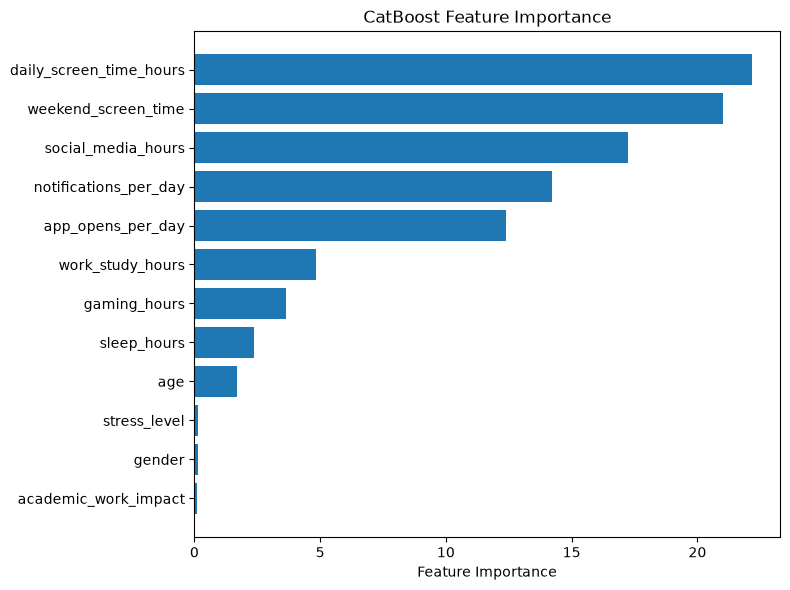

In [41]:
importance_plot = importance.sort_values(
    "importance",
    ascending=True
)

plt.figure(figsize=(8, 6))

plt.barh(
    importance_plot["feature"],
    importance_plot["importance"]
)

plt.xlabel("Feature Importance")
plt.title("CatBoost Feature Importance")

plt.tight_layout()
plt.show()

## 提出用ファイルを作成

In [42]:
test_pred_catboost = (
    final_catboost.predict_proba(X_test)[:, 1]
)

In [43]:
submission_catboost = (
    sample_submission.copy()
)

submission_catboost[
    TARGET
] = test_pred_catboost

display(
    submission_catboost.head()
)

,id,addicted_label
0,691369,0.999526
1,691370,0.958002
2,691371,0.937728
3,691372,0.989015
4,691373,0.998588


In [44]:
assert submission_catboost["id"].equals(
    test["id"]
)

assert submission_catboost[
    TARGET
].notna().all()

assert submission_catboost[
    TARGET
].between(0, 1).all()

print("Submission check OK")

Submission check OK


In [45]:
# 保存
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

submission_path = (
    OUTPUT_DIR
    / "submission_catboost.csv"
)

submission_catboost.to_csv(
    submission_path,
    index=False
)

print(submission_path)

c:\Users\Owner\Documents\projects\kaggle-study\output\smartphone_addiction\submission_catboost.csv


| Model    |       CV AUC | Public LB |
| -------- | -----------: | --------: |
| Logistic |     0.913787 |      提出結果 |
| HGB      |     0.957756 |      提出結果 |
| CatBoost | **0.963516** |      ← 今回 |
